In [1]:
import re
import numpy as np
import pandas as pd

from tqdm import tqdm
from datetime import datetime

import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

```sh
last reboot
last reboot -f /var/log/wtmp.1
```

In [2]:
with open('screen_time.txt', 'r') as file:
    lines_ = file.readlines()

In [3]:
uptime_df = pd.DataFrame({'DateAlone' : [], 'StartTime' : [], 'EndTime' : [], 'Uptime' : []})
year = datetime.now().year
dt_format = "%Y %a %b %d %H:%M"
st_dt_format = "%Y %a %b %d"

for line in tqdm(lines_):
    if 'generi' in line:
        time_string = re.sub(r'.*generi', '', line).strip()
        pattern = r"([A-Za-z]{3}\s+[A-Za-z]{3}\s+\d{1,2})\s+(\d{2}:\d{2})\s*-\s*(\d{2}:\d{2})\s*\((.*?)\)"
        match = re.search(pattern, time_string)
        date_str, start_time_str, end_time_str, uptime_str = match.groups()
        start_dt = datetime.strptime(f"{year} {date_str} {start_time_str}", dt_format)
        end_dt = datetime.strptime(f"{year} {date_str} {end_time_str}", dt_format)
        date_alone = datetime.strptime(f"{year} {date_str}", st_dt_format)
        uptime_df.loc[len(uptime_df)] = [date_alone, start_dt, end_dt, uptime_str]

100%|█████████████████████████████████████████████████████████████████████████████████| 405/405 [00:00<00:00, 1152.33it/s]


In [4]:
uptime_df['Uptime_delta'] = pd.to_timedelta(uptime_df["Uptime"] + ":00")
uptime_df["Uptime_minutes"] = uptime_df["Uptime_delta"].dt.total_seconds() / 60
uptime_df = uptime_df.query('Uptime_minutes > 0')

In [5]:
uptime_df["EndTime_"] = uptime_df["StartTime"] + uptime_df["Uptime_delta"]

In [6]:
uptime_df["Total_Daily_Uptime_minutes"] = uptime_df.groupby("DateAlone")["Uptime_minutes"].transform("sum")

In [7]:
uptime_df = uptime_df.sort_values('StartTime').reset_index(drop = True)

In [8]:
uptime_df.loc[uptime_df.Total_Daily_Uptime_minutes == uptime_df.Total_Daily_Uptime_minutes.max()]

,DateAlone,StartTime,EndTime,Uptime,Uptime_delta,Uptime_minutes,EndTime_,Total_Daily_Uptime_minutes
146,2026-07-17,2026-07-17 11:19:00,2026-07-17 18:24:00,07:04,0 days 07:04:00,424.0,2026-07-17 18:23:00,1262.0
147,2026-07-17,2026-07-17 11:50:00,2026-07-17 18:24:00,06:33,0 days 06:33:00,393.0,2026-07-17 18:23:00,1262.0
148,2026-07-17,2026-07-17 19:47:00,2026-07-17 03:13:00,07:25,0 days 07:25:00,445.0,2026-07-18 03:12:00,1262.0


In [9]:
for quartile in np.linspace(0.6, 1, 11):
    quartile_ = int(uptime_df["Total_Daily_Uptime_minutes"].quantile(quartile))
    print(f'{int(quartile * 100):3} -> {quartile_}')

 60 -> 736
 64 -> 754
 68 -> 757
 72 -> 769
 76 -> 780
 80 -> 792
 84 -> 809
 88 -> 829
 92 -> 848
 96 -> 879
100 -> 1262


In [10]:
uptime_df.query('Total_Daily_Uptime_minutes > 879')

,DateAlone,StartTime,EndTime,Uptime,Uptime_delta,Uptime_minutes,EndTime_,Total_Daily_Uptime_minutes
49,2026-06-02,2026-06-02 12:01:00,2026-06-02 17:12:00,05:11,0 days 05:11:00,311.0,2026-06-02 17:12:00,1075.0
50,2026-06-02,2026-06-02 12:20:00,2026-06-02 17:12:00,04:52,0 days 04:52:00,292.0,2026-06-02 17:12:00,1075.0
51,2026-06-02,2026-06-02 19:53:00,2026-06-02 03:45:00,07:52,0 days 07:52:00,472.0,2026-06-03 03:45:00,1075.0
85,2026-06-17,2026-06-17 10:13:00,2026-06-17 18:03:00,07:49,0 days 07:49:00,469.0,2026-06-17 18:02:00,894.0
86,2026-06-17,2026-06-17 19:34:00,2026-06-17 20:12:00,00:37,0 days 00:37:00,37.0,2026-06-17 20:11:00,894.0
87,2026-06-17,2026-06-17 20:20:00,2026-06-17 02:49:00,06:28,0 days 06:28:00,388.0,2026-06-18 02:48:00,894.0
102,2026-06-25,2026-06-25 09:33:00,2026-06-25 18:14:00,08:40,0 days 08:40:00,520.0,2026-06-25 18:13:00,947.0
103,2026-06-25,2026-06-25 19:32:00,2026-06-25 02:40:00,07:07,0 days 07:07:00,427.0,2026-06-26 02:39:00,947.0
128,2026-07-08,2026-07-08 11:09:00,2026-07-08 18:40:00,07:31,0 days 07:31:00,451.0,2026-07-08 18:40:00,898.0
129,2026-07-08,2026-07-08 20:02:00,2026-07-08 03:29:00,07:27,0 days 07:27:00,447.0,2026-07-09 03:29:00,898.0


In [11]:
uptime_df[uptime_df.duplicated(subset=["EndTime"], keep=False)]

,DateAlone,StartTime,EndTime,Uptime,Uptime_delta,Uptime_minutes,EndTime_,Total_Daily_Uptime_minutes
27,2026-05-23,2026-05-23 12:53:00,2026-05-23 13:38:00,00:44,0 days 00:44:00,44.0,2026-05-23 13:37:00,391.0
28,2026-05-23,2026-05-23 12:55:00,2026-05-23 13:38:00,00:42,0 days 00:42:00,42.0,2026-05-23 13:37:00,391.0
32,2026-05-25,2026-05-25 11:10:00,2026-05-25 11:43:00,00:32,0 days 00:32:00,32.0,2026-05-25 11:42:00,166.0
33,2026-05-25,2026-05-25 11:11:00,2026-05-25 11:43:00,00:31,0 days 00:31:00,31.0,2026-05-25 11:42:00,166.0
49,2026-06-02,2026-06-02 12:01:00,2026-06-02 17:12:00,05:11,0 days 05:11:00,311.0,2026-06-02 17:12:00,1075.0
50,2026-06-02,2026-06-02 12:20:00,2026-06-02 17:12:00,04:52,0 days 04:52:00,292.0,2026-06-02 17:12:00,1075.0
146,2026-07-17,2026-07-17 11:19:00,2026-07-17 18:24:00,07:04,0 days 07:04:00,424.0,2026-07-17 18:23:00,1262.0
147,2026-07-17,2026-07-17 11:50:00,2026-07-17 18:24:00,06:33,0 days 06:33:00,393.0,2026-07-17 18:23:00,1262.0
215,2026-08-17,2026-08-17 17:20:00,2026-08-17 18:36:00,01:16,0 days 01:16:00,76.0,2026-08-17 18:36:00,672.0
216,2026-08-17,2026-08-17 17:22:00,2026-08-17 18:36:00,01:14,0 days 01:14:00,74.0,2026-08-17 18:36:00,672.0


In [12]:
uptime_df = uptime_df.sort_values(by="Uptime_delta", ascending=False).drop_duplicates(subset=["EndTime"], keep="first")
uptime_df = uptime_df.sort_values('StartTime').reset_index(drop = True)

In [13]:
uptime_df["Total_Daily_Uptime_minutes"] = uptime_df.groupby("DateAlone")["Uptime_minutes"].transform("sum")

In [14]:
for quartile in np.linspace(0.6, 1, 11):
    quartile_ = int(uptime_df["Total_Daily_Uptime_minutes"].quantile(quartile))
    print(f'{int(quartile * 100):3} -> {quartile_}')

 60 -> 736
 64 -> 754
 68 -> 757
 72 -> 769
 76 -> 780
 80 -> 791
 84 -> 800
 88 -> 823
 92 -> 835
 96 -> 856
100 -> 947


In [15]:
uptime_df.query('Total_Daily_Uptime_minutes > 879')

,DateAlone,StartTime,EndTime,Uptime,Uptime_delta,Uptime_minutes,EndTime_,Total_Daily_Uptime_minutes
82,2026-06-17,2026-06-17 10:13:00,2026-06-17 18:03:00,07:49,0 days 07:49:00,469.0,2026-06-17 18:02:00,894.0
83,2026-06-17,2026-06-17 19:34:00,2026-06-17 20:12:00,00:37,0 days 00:37:00,37.0,2026-06-17 20:11:00,894.0
84,2026-06-17,2026-06-17 20:20:00,2026-06-17 02:49:00,06:28,0 days 06:28:00,388.0,2026-06-18 02:48:00,894.0
99,2026-06-25,2026-06-25 09:33:00,2026-06-25 18:14:00,08:40,0 days 08:40:00,520.0,2026-06-25 18:13:00,947.0
100,2026-06-25,2026-06-25 19:32:00,2026-06-25 02:40:00,07:07,0 days 07:07:00,427.0,2026-06-26 02:39:00,947.0
125,2026-07-08,2026-07-08 11:09:00,2026-07-08 18:40:00,07:31,0 days 07:31:00,451.0,2026-07-08 18:40:00,898.0
126,2026-07-08,2026-07-08 20:02:00,2026-07-08 03:29:00,07:27,0 days 07:27:00,447.0,2026-07-09 03:29:00,898.0
138,2026-07-15,2026-07-15 01:32:00,2026-07-15 02:34:00,01:02,0 days 01:02:00,62.0,2026-07-15 02:34:00,897.0
139,2026-07-15,2026-07-15 10:54:00,2026-07-15 17:50:00,06:55,0 days 06:55:00,415.0,2026-07-15 17:49:00,897.0
140,2026-07-15,2026-07-15 19:24:00,2026-07-15 02:24:00,07:00,0 days 07:00:00,420.0,2026-07-16 02:24:00,897.0


In [16]:
uptime_df

,DateAlone,StartTime,EndTime,Uptime,Uptime_delta,Uptime_minutes,EndTime_,Total_Daily_Uptime_minutes
0,2026-05-09,2026-05-09 12:11:00,2026-05-09 16:28:00,04:17,0 days 04:17:00,257.0,2026-05-09 16:28:00,400.0
1,2026-05-09,2026-05-09 21:33:00,2026-05-09 23:57:00,02:23,0 days 02:23:00,143.0,2026-05-09 23:56:00,400.0
2,2026-05-10,2026-05-10 22:04:00,2026-05-10 00:59:00,02:54,0 days 02:54:00,174.0,2026-05-11 00:58:00,174.0
3,2026-05-11,2026-05-11 12:07:00,2026-05-11 18:02:00,05:54,0 days 05:54:00,354.0,2026-05-11 18:01:00,733.0
4,2026-05-11,2026-05-11 19:59:00,2026-05-11 02:18:00,06:19,0 days 06:19:00,379.0,2026-05-12 02:18:00,733.0
...,...,...,...,...,...,...,...,...
377,2026-10-19,2026-10-19 11:34:00,2026-10-19 18:14:00,06:39,0 days 06:39:00,399.0,2026-10-19 18:13:00,688.0
378,2026-10-19,2026-10-19 20:08:00,2026-10-19 00:56:00,04:48,0 days 04:48:00,288.0,2026-10-20 00:56:00,688.0
379,2026-10-20,2026-10-20 11:20:00,2026-10-20 11:25:00,00:05,0 days 00:05:00,5.0,2026-10-20 11:25:00,27.0
380,2026-10-20,2026-10-20 11:44:00,2026-10-20 12:04:00,00:19,0 days 00:19:00,19.0,2026-10-20 12:03:00,27.0


In [17]:
daily_df = uptime_df.groupby("DateAlone")["Total_Daily_Uptime_minutes"].first().reset_index()
daily_df

,DateAlone,Total_Daily_Uptime_minutes
0,2026-05-09,400.0
1,2026-05-10,174.0
2,2026-05-11,733.0
3,2026-05-12,525.0
4,2026-05-13,791.0
...,...,...
160,2026-10-16,455.0
161,2026-10-17,572.0
162,2026-10-18,682.0
163,2026-10-19,688.0


In [18]:
daily_df['Net_Daily_Uptime_minutes'] = daily_df.Total_Daily_Uptime_minutes - 60 - 60 - 60

In [19]:
daily_df.query('Net_Daily_Uptime_minutes < 0')

,DateAlone,Total_Daily_Uptime_minutes,Net_Daily_Uptime_minutes
1,2026-05-10,174.0,-6.0
16,2026-05-25,135.0,-45.0
164,2026-10-20,27.0,-153.0


In [20]:
daily_df = daily_df.query('Net_Daily_Uptime_minutes > 0')

In [21]:
daily_df['Net_Daily_Uptime_minutes'] = daily_df.Net_Daily_Uptime_minutes/60

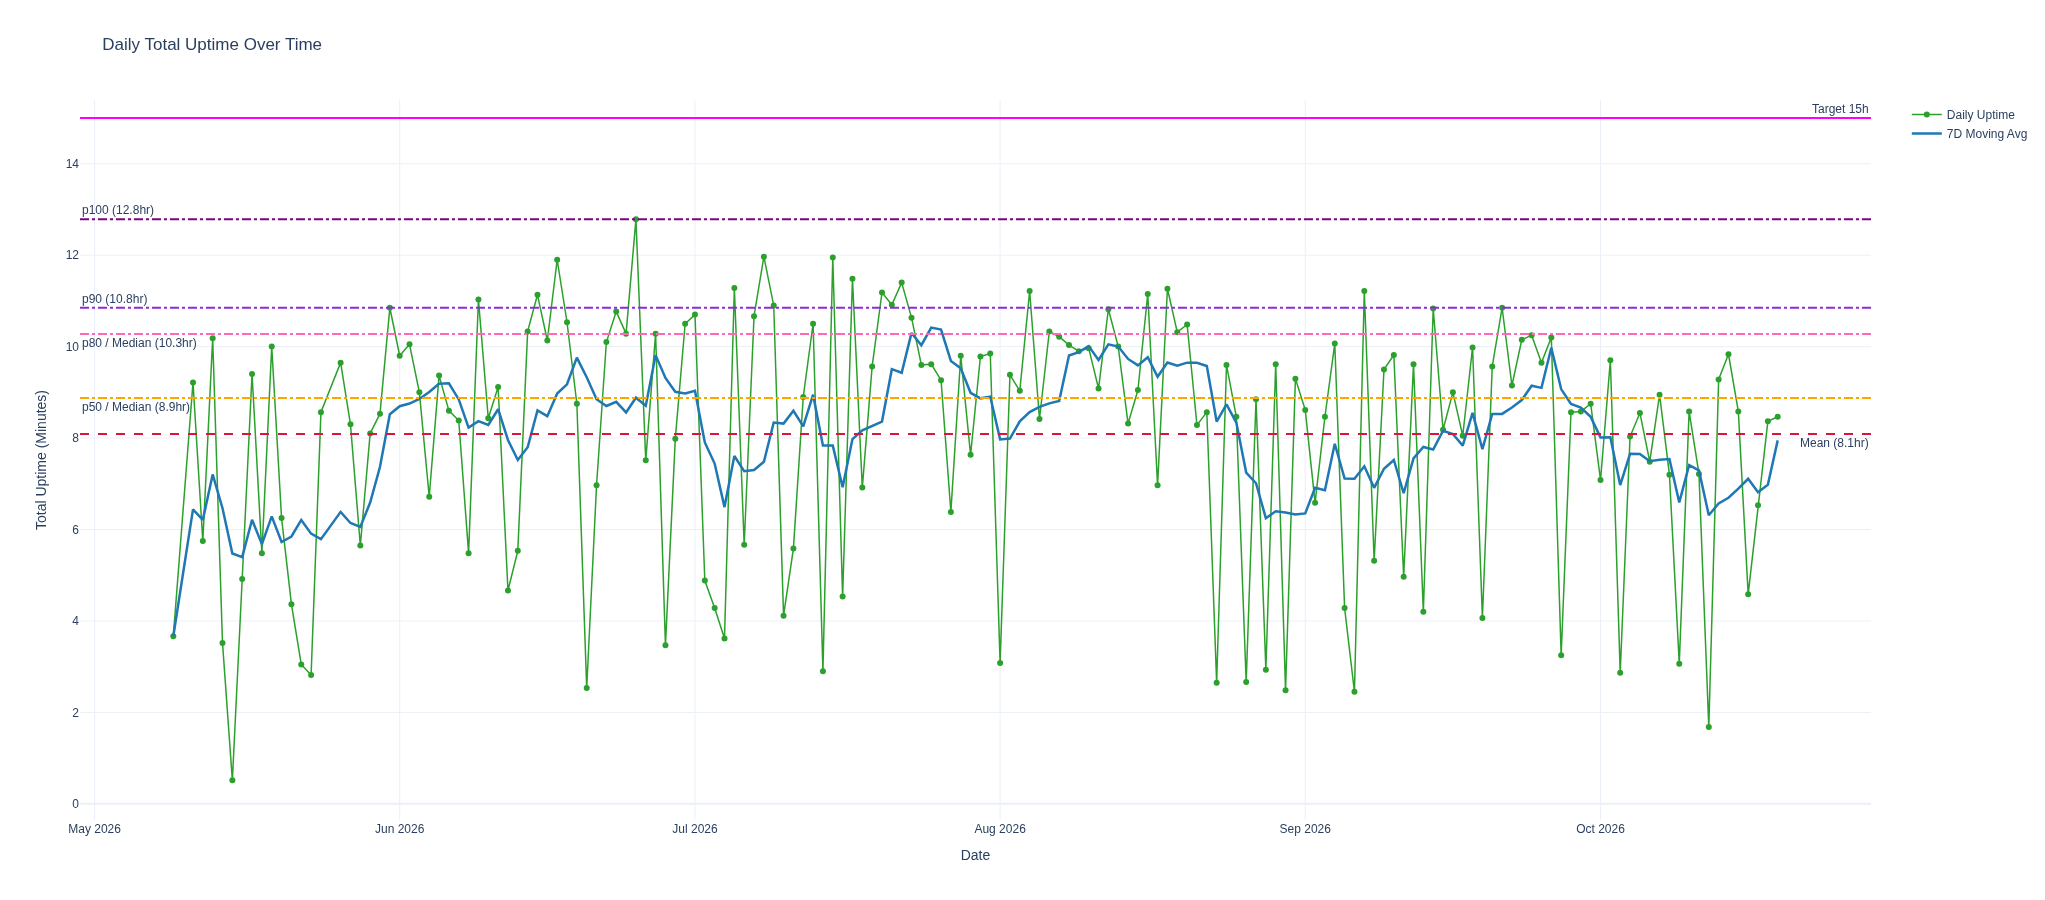

In [22]:
daily_df["Rolling_Avg"] = daily_df["Net_Daily_Uptime_minutes"].rolling(7, min_periods=1).mean()

avg_val = daily_df["Net_Daily_Uptime_minutes"].mean()
p50_val = daily_df["Net_Daily_Uptime_minutes"].quantile(0.50)
p80_val = daily_df["Net_Daily_Uptime_minutes"].quantile(0.80)
p90_val = daily_df["Net_Daily_Uptime_minutes"].quantile(0.90)
p100_val = daily_df["Net_Daily_Uptime_minutes"].quantile(1)

fig = go.Figure()
fig.add_trace(go.Scatter(x=daily_df["DateAlone"], y=daily_df["Net_Daily_Uptime_minutes"],
                         mode="lines+markers", name="Daily Uptime",
                         line=dict(color="#2ca02c", width=1.5), marker=dict(size=6),
                         hovertemplate="<b>Date:</b> %{x|%Y-%m-%d}<br><b>Uptime:</b> %{y:.1f} hrs<extra></extra>"))

fig.add_trace(go.Scatter(x=daily_df["DateAlone"], y=daily_df["Rolling_Avg"], mode="lines",
                         name="7D Moving Avg", line=dict(color="#1f77b4", width=2.5),
                         hovertemplate="<b>7D Avg:</b> %{y:.1f} hrs<extra></extra>"))
fig.add_hline(y=avg_val, line_dash="dash", line_color="crimson",
              annotation_text=f"Mean ({avg_val:.1f}hr)", annotation_position="bottom right")
fig.add_hline(y=p100_val, line_dash="dashdot", line_color="purple",
              annotation_text=f"p100 ({p100_val:.1f}hr)", annotation_position="top left")
fig.add_hline(y=p90_val, line_dash="dashdot", line_color="blueviolet",
              annotation_text=f"p90 ({p90_val:.1f}hr)", annotation_position="top left")
fig.add_hline(y=p80_val, line_dash="dashdot", line_color="hotpink",
              annotation_text=f"p80 / Median ({p80_val:.1f}hr)", annotation_position="bottom left")
fig.add_hline(y=p50_val, line_dash="dashdot", line_color="orange",
              annotation_text=f"p50 / Median ({p50_val:.1f}hr)", annotation_position="bottom left")
fig.add_hline(y=15, line_dash="solid", line_color="magenta",
              annotation_text="Target 15h", annotation_position="top right")
fig.update_layout(title="Daily Total Uptime Over Time", xaxis_title="Date",
                  yaxis_title="Total Uptime (Minutes)", hovermode="x unified",
                  template="plotly_white", height=900)
fig.show()

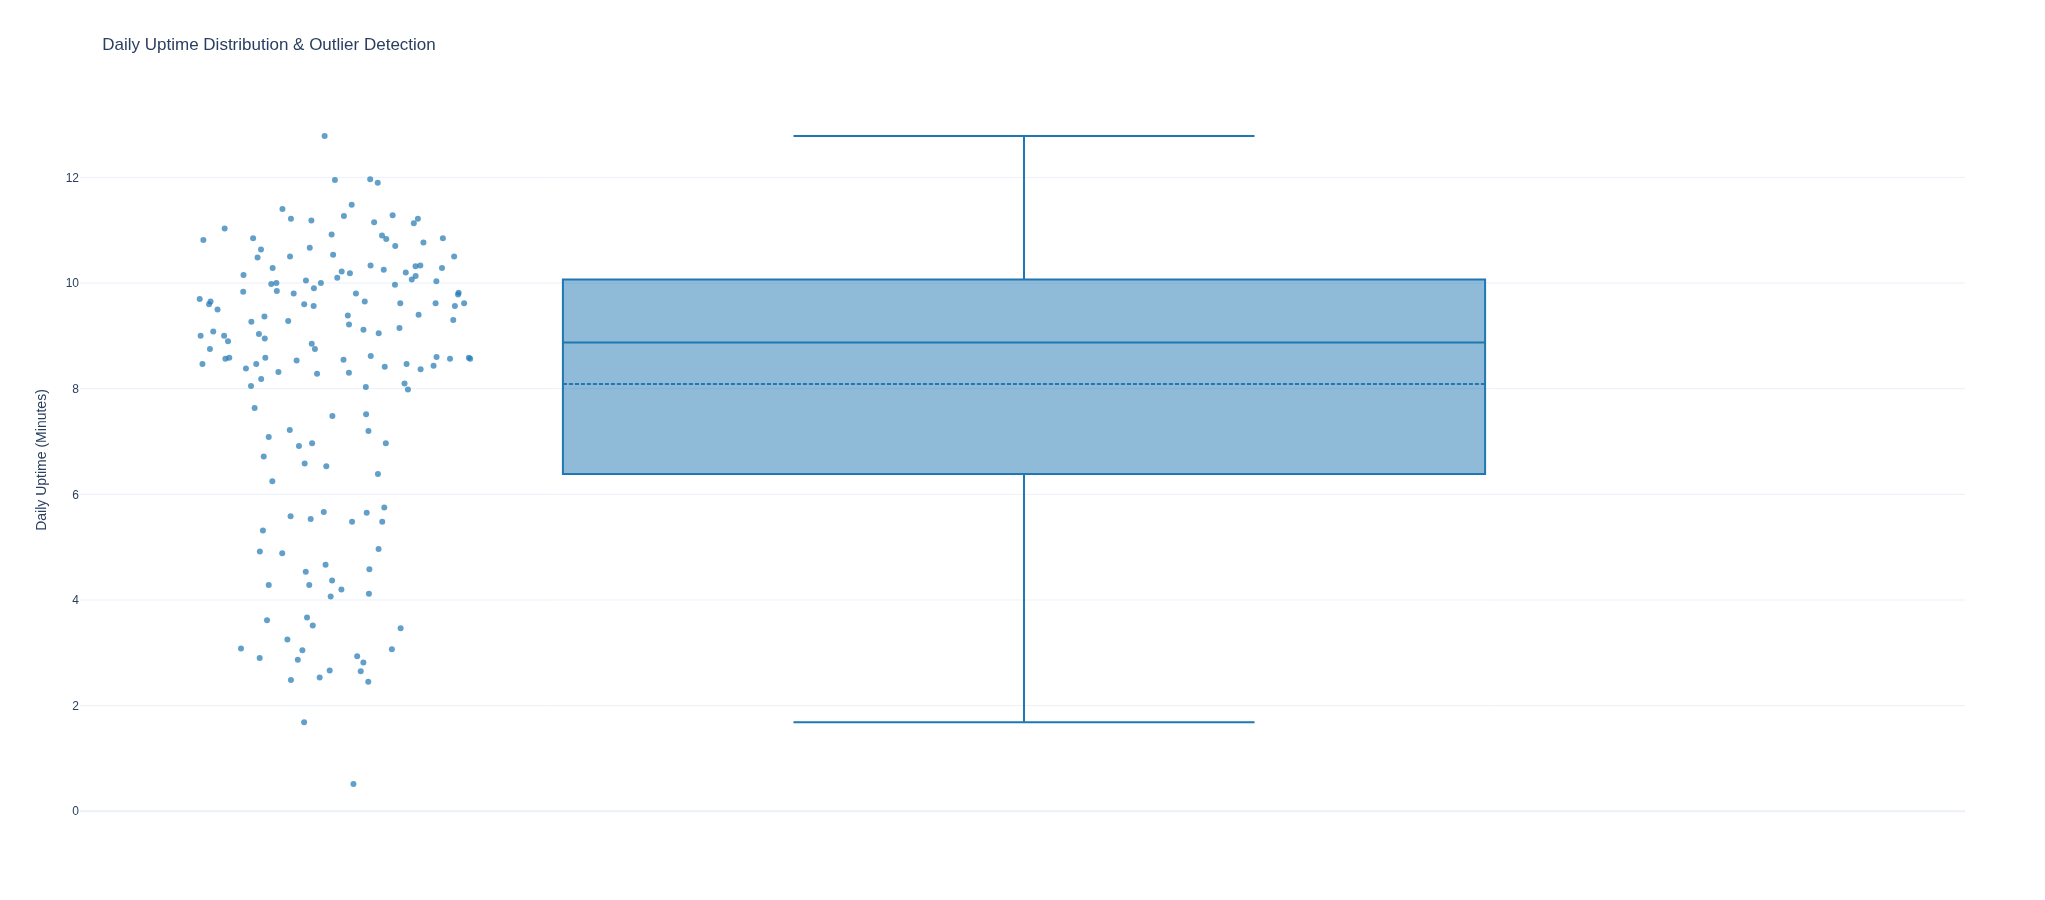

In [23]:
fig = px.box(daily_df, y="Net_Daily_Uptime_minutes", points="all", notched=False,
             title="Daily Uptime Distribution & Outlier Detection",
             labels={"Net_Daily_Uptime_minutes": "Daily Uptime (Minutes)"},
             template="plotly_white")

fig.update_traces(marker=dict(size=6, opacity=0.7, color="#1f77b4"), boxmean=True)
fig.update_layout(height=900)
fig.show()